# Baseline Model: TF-IDF + Logistic Regression

This notebook implements a simple baseline for AI-generated text detection.

## Pipeline
1. Load preprocessed train / validation / test splits
2. Build a TF-IDF + Logistic Regression pipeline
3. Train the baseline model
4. Evaluate on validation and test sets
5. Show confusion matrix and sample prediction confidence
6. Save the trained baseline model

## Input files
- `datasets/splits/train.parquet`
- `datasets/splits/val.parquet`
- `datasets/splits/test.parquet`

In [6]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# =========================
# Path fix (VERY IMPORTANT)
# =========================
train_path = "../datasets/splits/train.parquet"
val_path   = "../datasets/splits/val.parquet"
test_path  = "../datasets/splits/test.parquet"

# check path
for path in [train_path, val_path, test_path]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

# =========================
# Load data
# =========================
train_df = pd.read_parquet(train_path)
val_df   = pd.read_parquet(val_path)
test_df  = pd.read_parquet(test_path)

print("Train:", train_df.shape)
print("Val  :", val_df.shape)
print("Test :", test_df.shape)

# =========================
# Prepare data
# =========================
train_sample_size = 100000
val_sample_size = 20000
test_sample_size = 20000

train_df_small = train_df.sample(min(train_sample_size, len(train_df)), random_state=42)
val_df_small = val_df.sample(min(val_sample_size, len(val_df)), random_state=42)
test_df_small = test_df.sample(min(test_sample_size, len(test_df)), random_state=42)

X_train = train_df_small["text"].astype(str)
y_train = train_df_small["label"].astype(int)

X_val = val_df_small["text"].astype(str)
y_val = val_df_small["label"].astype(int)

X_test = test_df_small["text"].astype(str)
y_test = test_df_small["label"].astype(int)

label_map = {
    0: "Human-written",
    1: "AI-generated"
}

print("Sampled train size:", len(X_train))
print("Sampled val size  :", len(X_val))
print("Sampled test size :", len(X_test))

Train: (985525, 3)
Val  : (211184, 3)
Test : (211185, 3)
Sampled train size: 100000
Sampled val size  : 20000
Sampled test size : 20000


In [7]:
# =========================
# Build + Train model
# =========================

baseline_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 1),
        max_features=10000
    )),
    ("clf", LogisticRegression(
        max_iter=300,
        random_state=42
    ))
])

baseline_model.fit(X_train, y_train)

print("Training complete.")

Training complete.



===== Validation Results =====
Accuracy : 0.8777
Precision: 0.7936
Recall   : 0.7256
F1-score : 0.7581

              precision    recall  f1-score   support

           0     0.9044    0.9323    0.9181     14716
           1     0.7936    0.7256    0.7581      5284

    accuracy                         0.8777     20000
   macro avg     0.8490    0.8289    0.8381     20000
weighted avg     0.8751    0.8777    0.8758     20000


===== Test Results =====
Accuracy : 0.8833
Precision: 0.8115
Recall   : 0.7339
F1-score : 0.7707

              precision    recall  f1-score   support

           0     0.9062    0.9378    0.9218     14657
           1     0.8115    0.7339    0.7707      5343

    accuracy                         0.8833     20000
   macro avg     0.8589    0.8359    0.8462     20000
weighted avg     0.8809    0.8833    0.8814     20000



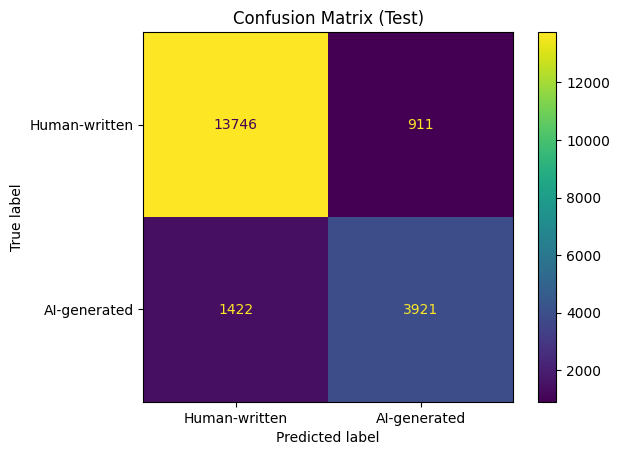

In [8]:
# =========================
# Evaluation function
# =========================

def evaluate(model, X, y, name="Test"):
    pred = model.predict(X)
    prob = model.predict_proba(X)[:, 1]

    acc = accuracy_score(y, pred)
    precision = precision_score(y, pred, zero_division=0)
    recall = recall_score(y, pred, zero_division=0)
    f1 = f1_score(y, pred, zero_division=0)

    print(f"\n===== {name} Results =====")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-score : {f1:.4f}")
    print()
    print(classification_report(y, pred, digits=4))

    return pred, prob


# =========================
# Validation
# =========================
val_pred, val_prob = evaluate(baseline_model, X_val, y_val, "Validation")

# =========================
# Test
# =========================
test_pred, test_prob = evaluate(baseline_model, X_test, y_test, "Test")

# =========================
# Confusion Matrix
# =========================
cm = confusion_matrix(y_test, test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Human-written", "AI-generated"]
)

disp.plot()
plt.title("Confusion Matrix (Test)")
plt.show()

In [9]:
# =========================
# Example prediction
# =========================

sample_text = "This essay explores the impact of artificial intelligence on education."

pred = baseline_model.predict([sample_text])[0]
proba = baseline_model.predict_proba([sample_text])[0]
confidence = proba[pred]

print("Input:", sample_text)
print("Prediction:", label_map[pred])
print("Confidence:", round(confidence, 4))


# =========================
# Save model
# =========================

joblib.dump(baseline_model, "baseline_model.joblib")
print("\nModel saved as baseline_model.joblib")

Input: This essay explores the impact of artificial intelligence on education.
Prediction: Human-written
Confidence: 0.9168

Model saved as baseline_model.joblib


## Conclusion

This project implemented a simple baseline model for AI-generated text detection using TF-IDF features and Logistic Regression, in line with the requirement to keep the baseline approach simple and interpretable.

### Key Results
- The model achieved strong overall performance:
  - Validation Accuracy: 0.8777 | Test Accuracy: 0.8833  
  - Validation F1-score: 0.7581 | Test F1-score: 0.7707  
- The close alignment between validation and test results indicates good generalisation and minimal overfitting.
- The model performs significantly better on human-written text (F1 ≈ 0.9181) than on AI-generated text (F1 ≈ 0.7581).

### Key Observations
- The recall for AI-generated text is relatively low (≈ 0.73), meaning a considerable number of AI-generated samples are misclassified as human-written.
- This suggests that AI-generated text shares strong surface-level similarities with human writing, making it difficult for traditional models to distinguish between the two.
- The model demonstrates a bias toward predicting the majority class (human-written text), which is consistent with the dataset distribution.

### Limitations of the Baseline
- The TF-IDF representation relies on lexical frequency and does not capture deeper semantic or contextual information.
- As a result, the model struggles with subtle linguistic patterns and more sophisticated AI-generated text.
- This limitation explains the performance gap between the two classes.

### Alignment with Project Requirements
- The baseline model remains intentionally simple, serving as a reference point for evaluating more advanced approaches.
- The model outputs prediction probabilities, which can be interpreted as confidence scores, aligning with the requirement to report classifier confidence.
- Further improvement could involve calibrating these probabilities to produce more reliable confidence estimates.
